# Evidence-Oriented AI Co-Scientist

Check research claims against executable numerical evidence, preserve the evidence chain, and use NVIDIA NIM to explain the checked result. NeMo Fabric controls the custom agent lifecycle and NeMo Relay records tool/model activity.

Start with the authored fixture. A real run needs the stated credentials and compute. Failed executions stop the cell and remain saved; they are never replaced by fixture success.

- [Original EOP teaching project](https://github.com/virginiakm1988/EOP_agent_tutorial)
- [NeMo Fabric](https://github.com/NVIDIA/NeMo-Fabric)
- [NeMo Relay](https://github.com/NVIDIA/NeMo-Relay)
- [NeMo Helix](https://github.com/NVIDIA-NeMo/nemo-helix)

In [ ]:
import os, pathlib, subprocess, sys
REPO_URL = "https://github.com/virginiakm1988/ai-coscientist-nvidia.git"
GIT_REF = "v0.1.0"  # Published source used for the recorded validation.
checkout = pathlib.Path("/content/ai-coscientist-nvidia")
if not checkout.exists():
    subprocess.run(["git", "clone", REPO_URL, str(checkout)], check=True)
subprocess.run(["git", "-C", str(checkout), "checkout", GIT_REF], check=True)
os.chdir(checkout)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[agents,notebook]"], check=True)
print("Source revision:", subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip())


## Architecture

The diagram is authored for this tutorial. Each arrow maps to executable package code. Fixture and live results remain explicitly separated.

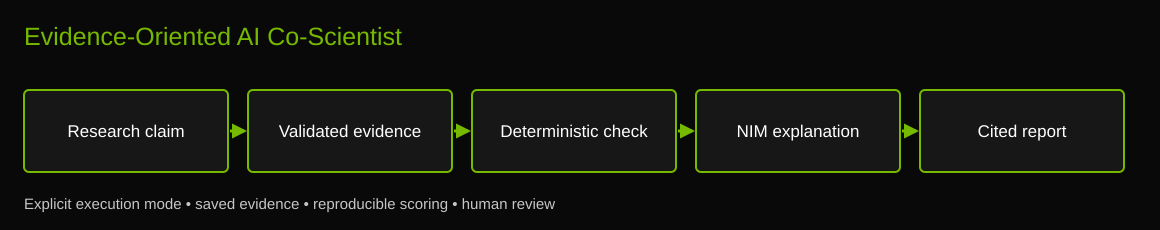

In [2]:
from IPython.display import SVG, display
display(SVG(filename="assets/overview.svg"))

In [3]:
import ipywidgets as widgets
from IPython.display import display
mode = widgets.Dropdown(options=[("Authored fixture (no model)", "fixture"), ("Real model (credentials/resources required)", "live")], value="fixture", description="Mode")
display(mode)


Dropdown(description='Mode', options=(('Authored fixture (no model)', 'fixture'), ('Real model (credentials/re…

In [4]:
# Credentials remain in the process environment and are never printed.
if mode.value == "live":
    try:
        from google.colab import userdata
        os.environ["NVIDIA_API_KEY"] = userdata.get("NVIDIA_API_KEY")
    except ImportError:
        if not os.environ.get("NVIDIA_API_KEY"):
            raise RuntimeError("Set NVIDIA_API_KEY in the environment before live execution")


In [5]:
import json
settings = json.loads(pathlib.Path("configs/default.json").read_text())
raw = json.loads((pathlib.Path("configs") / settings["data"]).read_text(encoding="utf-8"))
cases = raw["queries"] if isinstance(raw, dict) else raw
selection = widgets.Dropdown(options=[("All scenarios", "")] + [(row.get("question", row["id"]), row["id"]) for row in cases], description="Scenario")
display(selection)


Dropdown(description='Scenario', options=(('All scenarios', ''), ('matching-results', 'matching-results'), ('m…

In [6]:
command = [sys.executable, "-m", "project_demo", "demo", "--mode", mode.value, "--output-dir", "runs/colab"]
if selection.value: command += ["--case", selection.value]
subprocess.run(command, check=True)
import json
latest = json.loads(pathlib.Path("runs/colab/latest.json").read_text())
result_file = pathlib.Path(latest["run"]) / "result.json"
record = json.loads(result_file.read_text(encoding="utf-8"))
print("Execution mode:", record["mode"], "Status:", record["status"])
display(record["result"])


Execution mode: fixture Status: succeeded


{'scenarios': [{'id': 'matching-results',
   'expected_status': 'supported',
   'check': {'status': 'supported',
    'value': 11.0,
    'citations': ['baseline', 'candidate'],
    'reason': 'Computed (candidate correct/total - baseline correct/total) × 100.',
    'evidence_chain': [{'id': 'baseline',
      'sha256': 'de39652793ed784b9a6f3a0c2ef24e90a6e23cc7b27acf752c4c11e83f79076d',
      'artifact': {'correct': 80,
       'total': 100,
       'evaluation_set_sha256': 'demo-heldout-v1'}},
     {'id': 'candidate',
      'sha256': '47e7e331d8e6ca7788b41b915c301126ae8d591ddd2f678ed30902cd97c6c173',
      'artifact': {'correct': 91,
       'total': 100,
       'evaluation_set_sha256': 'demo-heldout-v1'}}]},
   'answer': {'summary': 'Computed (candidate correct/total - baseline correct/total) × 100.',
    'status': 'supported',
    'citations': ['baseline', 'candidate'],
    'model_called': False}},
  {'id': 'missing-evidence',
   'expected_status': 'unsupported',
   'check': {'status': 'un

## Inspect the outcome

Claim-decision accuracy is scored against the authored case labels. A complete citation chain does not prove experimental validity; the numerical experiment itself and the prose explanation still require human review.

Change one input/configuration at a time, rerun, and compare saved result files. Do not compare authored-fixture scores with live scores as model performance.

## Recorded real NVIDIA execution

The following saved result comes from an actual live NIM run through Fabric and Relay. It is separate from the authored fixture above.


In [7]:
import json
display(json.loads(pathlib.Path("evidence/live-nim-fabric.json").read_text(encoding="utf-8")))


{'command': 'demo',
 'mode': 'live',
 'status': 'succeeded',
 'config': {'project': 'ai-coscientist',
  'data': '../data/scenarios.json',
  'model': 'nvidia/nemotron-3.5-lightning-30b-a3b',
  'base_url': 'https://integrate.api.nvidia.com/v1',
  'max_requests': 12},
 'config_sha256': '45a5bdeec8621309065e81548b9212f183587eee37aec3e4742e7d8199d06a8e',
 'started_at': '2026-11-16T09:08:10.197476+00:00',
 'python': '3.12.14',
 'result': {'agent_name': 'ai-coscientist',
  'harness': 'virginia.demo.ai-coscientist',
  'adapter_kind': 'python',
  'adapter_id': 'virginia.demo.ai-coscientist',
  'runtime_id': 'runtime-1794820090900-20180-2',
  'invocation_id': 'invocation-1794820091302-20180-5',
  'request_id': 'request-ebd7a9a708624d898766258fe4f81c78',
  'status': 'succeeded',
  'output': {'method': 'deterministic evidence chain plus NIM explanation',
   'metrics': {'claim_decision_accuracy': 1.0,
    'n': 4,
    'narrative_quality': 'requires_human_review',
    'numeric_checks_are_deterministi